**ESOPHAGEAL CANCER CLASSIFICATION USING INCEPTIONV3 FOR SAVE IMAGES**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
import matplotlib.pyplot as plt

train_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/SAVE_split/train'
val_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/SAVE_split/val'
test_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/SAVE_split/test'

# Parameters
IMAGE_SIZE = (640, 640)  # InceptionV3 requires images of size 299x299
BATCH_SIZE = 32
EPOCHS = 100

# Load datasets
train_dataset = image_dataset_from_directory(
    train_dir,
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE
)

val_dataset = image_dataset_from_directory(
    val_dir,
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE
)

test_dataset = image_dataset_from_directory(
    test_dir,
    shuffle=False,
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE
)



Found 751 files belonging to 3 classes.
Found 214 files belonging to 3 classes.
Found 109 files belonging to 3 classes.


In [ ]:
# Define data augmentation
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
])

# Preprocess input for InceptionV3
preprocess_input = tf.keras.applications.inception_v3.preprocess_input

# Load InceptionV3 model without the top layer
base_model = InceptionV3(weights='imagenet', include_top=False, input_shape=(640, 640, 3))

# Freeze the base model layers
base_model.trainable = False

# Build model
inputs = tf.keras.Input(shape=(640, 640, 3))
x = data_augmentation(inputs)  # Apply data augmentation
x = preprocess_input(x)        # Preprocess input
x = base_model(x, training=False)  # Pass through base model
x = GlobalAveragePooling2D()(x)  # Global Average Pooling
x = Dropout(0.5)(x)              # Regularization with Dropout

# Determine the number of classes
num_classes = len(train_dataset.class_names) # Get number of classes from class_names
outputs = Dense(num_classes, activation='softmax')(x)  # Output layer

model = Model(inputs, outputs)

# Compile model
model.compile(optimizer=tf.keras.optimizers.Adam(),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 640, 640, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ sequential (Sequential)              │ (None, 640, 640, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ true_divide (TrueDivide)             │ (None, 640, 640, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ subtract (Subtract)                  │ (None, 640, 640, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ inception_v3 (Functional)            │ (None, 18, 18, 2048)        │      21,802,784 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 3)                   │           6,147 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 21,808,931 (83.19 MB)

 Trainable params: 6,147 (24.01 KB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [ ]:
# Train the model without callbacks
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)



Epoch 1/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 230s 9s/step - accuracy: 0.3923 - loss: 1.1199 - val_accuracy: 0.6636 - val_loss: 0.8649
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 62s 856ms/step - accuracy: 0.5656 - loss: 0.9187 - val_accuracy: 0.7383 - val_loss: 0.7670
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 40s 815ms/step - accuracy: 0.6578 - loss: 0.8444 - val_accuracy: 0.7804 - val_loss: 0.7216
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 21s 828ms/step - accuracy: 0.6669 - loss: 0.7965 - val_accuracy: 0.7710 - val_loss: 0.6582
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 20s 818ms/step - accuracy: 0.6980 - loss: 0.7382 - val_accuracy: 0.7804 - val_loss: 0.6172
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 20s 811ms/step - accuracy: 0.6760 - loss: 0.7495 - val_accuracy: 0.7804 - val_loss: 0.5903
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 21s 816ms/step - accuracy: 0.7268 - loss: 0.6946 - val_accuracy: 0.7570 - val_loss: 0.5762
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 20s 850ms/step - accuracy: 0.7104 - loss: 0.6752 - va

In [ ]:
# Evaluate the model on the test set
test_loss, test_accuracy = model.evaluate(test_dataset)
print(f'Test Accuracy: {test_accuracy * 100:.2f}%')



4/4 ━━━━━━━━━━━━━━━━━━━━ 32s 8s/step - accuracy: 0.8574 - loss: 0.4141
Test Accuracy: 84.40%


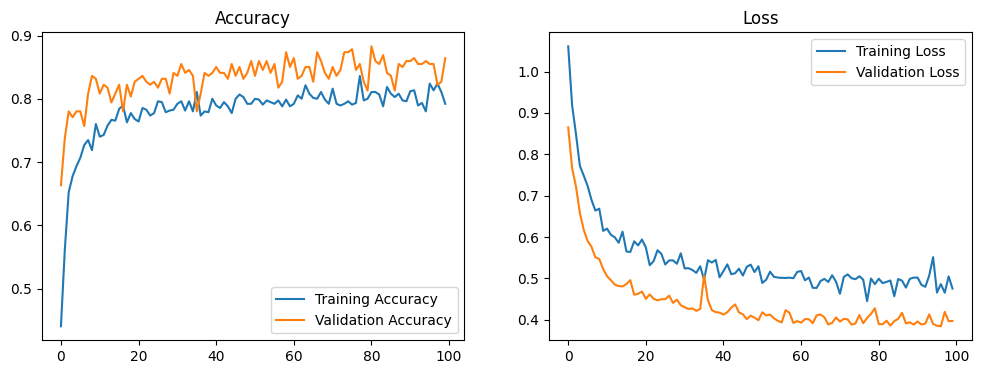

In [ ]:
# Plot training history
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title('Loss')

plt.show()



In [ ]:
# Generate Classification Report
from sklearn.metrics import classification_report
import numpy as np

y_true = np.concatenate([y for x, y in test_dataset], axis=0)
y_pred = np.argmax(model.predict(test_dataset), axis=1)

print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=test_dataset.class_names))


4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step
Classification Report:
              precision    recall  f1-score   support

   Dysplasia       0.77      0.90      0.83        41
      Normal       0.97      0.85      0.91        34
         SCC       0.84      0.76      0.80        34

    accuracy                           0.84       109
   macro avg       0.86      0.84      0.85       109
weighted avg       0.85      0.84      0.84       109



In [ ]:
import tensorflow as tf

model.save_weights('/content/drive/MyDrive/today/inception_trick_folder/my_model_inceptionv3_saveREAL_weights.weights.h5')  # Add '.weights' before '.h5'


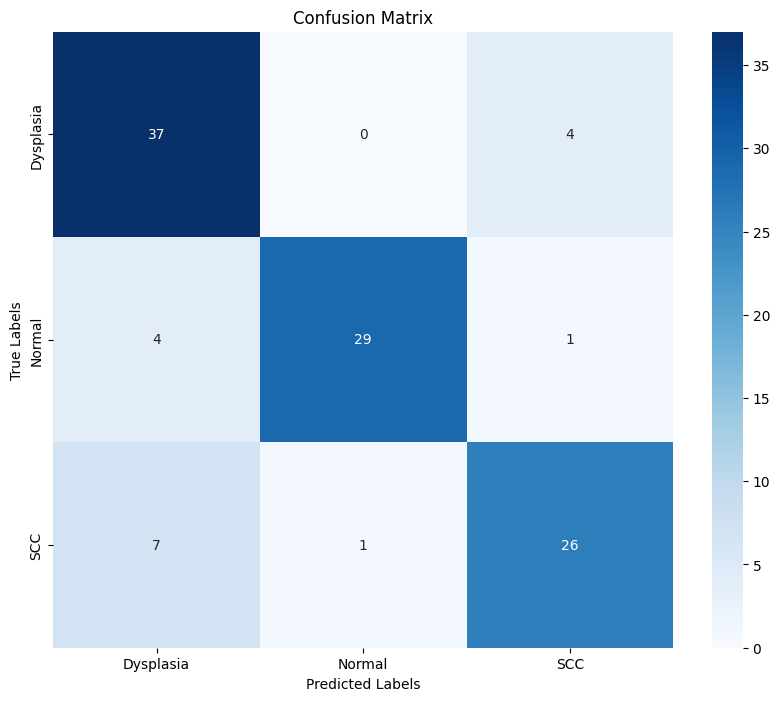

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=test_dataset.class_names, yticklabels=test_dataset.class_names)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Load the saved model weights
model.load_weights('/content/drive/MyDrive/today/inception_trick_folder/my_model_inceptionv3_saveREAL_weights.weights.h5')

# Get a batch of images and labels from the test dataset
images, labels = next(iter(test_dataset))

# Select 12 images
num_images_to_display = 12
images_to_display = images[:num_images_to_display]
labels_to_display = labels[:num_images_to_display]

# Predict the labels for the selected images
predictions = model.predict(images_to_display)
predicted_labels = np.argmax(predictions, axis=1)
confidence = np.max(predictions, axis=1)

# Display the images with their true and predicted labels
plt.figure(figsize=(15, 10))
for i in range(num_images_to_display):
  plt.subplot(3, 4, i + 1)
  plt.imshow(images_to_display[i].numpy().astype("uint8"))
  plt.title(f"True: {test_dataset.class_names[labels_to_display[i]]}\nPred: {test_dataset.class_names[predicted_labels[i]]}\nConf: {confidence[i]:.2f}")
  plt.axis("off")

plt.tight_layout()
plt.show()


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.utils import image_dataset_from_directory # Make sure to import the function

# Load the saved model weights
model.load_weights('/content/drive/MyDrive/new_dataset_EC/ec/EC/final/InceptionV3/SAVE_Inception/my_model_inceptionv3_saveREAL_weights.weights.h5')

# Define the path to the SCC folder in the test dataset
scc_test_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/SAVE_split/test/'

# Print the directory contents to check for images
!ls '{scc_test_dir}'

# Create a new image dataset from the SCC folder
scc_test_dataset = image_dataset_from_directory(
    scc_test_dir,
    shuffle=False,
    batch_size=32,  # Replace with your actual BATCH_SIZE
    image_size=(640, 640)  # Replace with your actual IMAGE_SIZE
)

# Get a batch of images and labels from the SCC test dataset
images, labels = next(iter(scc_test_dataset))

# Select 12 images
num_images_to_display = 12
images_to_display = images[:num_images_to_display]
labels_to_display = labels[:num_images_to_display]

# Predict the labels for the selected images
predictions = model.predict(images_to_display)
predicted_labels = np.argmax(predictions, axis=1)
confidence = np.max(predictions, axis=1)

# Display the images with their true and predicted labels
plt.figure(figsize=(15, 10))
for i in range(num_images_to_display):
  plt.subplot(3, 4, i + 1)
  plt.imshow(images_to_display[i].numpy().astype("uint8"))
  plt.title(f"True: {scc_test_dataset.class_names[labels_to_display[i]]}\nPred: {scc_test_dataset.class_names[predicted_labels[i]]}\nConf: {confidence[i]:.2f}")  # Use scc_test_dataset.class_names for both true and predicted labels
  plt.axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.